In [23]:

!pip -q install gdown

import gdown
import os
import glob

folder_url = "https://drive.google.com/drive/folders/1BCTayfVYwapGcGl3Mizik1E6-zPcQ_DT?usp=sharing"

os.makedirs("/content/campaign_data", exist_ok=True)

gdown.download_folder(
    url=folder_url,
    output="/content/campaign_data",
    quiet=False
)

files = glob.glob("/content/campaign_data/**/*.csv", recursive=True)

for file in files:
    print(file)


Retrieving folder contents


Processing file 1m3ZO0DctdhpAsF2eyZcKxswkZ5VuurRa messy_test_data.csv
Processing file 17mNOMu0x-8Br9t3J2f0dcLrfq24eWv5Z messy_train_data.csv


Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1m3ZO0DctdhpAsF2eyZcKxswkZ5VuurRa
To: /content/campaign_data/messy_test_data.csv
100%|██████████| 162k/162k [00:00<00:00, 61.0MB/s]
Downloading...
From: https://drive.google.com/uc?id=17mNOMu0x-8Br9t3J2f0dcLrfq24eWv5Z
To: /content/campaign_data/messy_train_data.csv
100%|██████████| 709k/709k [00:00<00:00, 123MB/s]

/content/campaign_data/messy_train_data.csv
/content/campaign_data/messy_test_data.csv



Download completed


In [24]:

import pandas as pd
import numpy as np

train_path = "/content/campaign_data/messy_train_data.csv"
test_path = "/content/campaign_data/messy_test_data.csv"

train_raw = pd.read_csv(train_path)
test_raw = pd.read_csv(test_path)

print("TRAINING DATA")
print("Shape:", train_raw.shape)
print("Columns:", train_raw.columns.tolist())
display(train_raw.head())

print("\nTEST DATA")
print("Shape:", test_raw.shape)
print("Columns:", test_raw.columns.tolist())
display(test_raw.head())

print("\nMISSING VALUES IN TRAINING DATA")
display(train_raw.isnull().sum().sort_values(ascending=False))

print("\nDATA TYPES")
display(train_raw.dtypes.to_frame("Data Type"))

print("\nDUPLICATE ROWS:", train_raw.duplicated().sum())


TRAINING DATA
Shape: (8000, 8)
Columns: ['Followers', 'EngagementRate (%)', 'AdSpend (GBP)', 'ContentQuality', 'Sales (Units)', 'ID', 'Timestamp', 'Notes']


,Followers,EngagementRate (%),AdSpend (GBP),ContentQuality,Sales (Units),ID,Timestamp,Notes
0,106572.0,2.573174871146172,2614.3781948587675,5.275680,6340,9254,2021-11-27,Pending
1,77583.0,0.9394984315675532,4975.962514379572,8.756268,5793,1561,2022-02-13,Review
2,92832.0,2.1761012652155296,4107.769534318886,6.454727,8104,1670,2023-09-25,Pending
3,53565.0,1.4783757541486553,4293.330464613049,4.312813,7293,6087,2023-02-15,Review
4,121079.0,3.3741976179329356,5343.549440897207,3.769047,14396,6669,2023-05-28,NaN



TEST DATA
Shape: (2000, 7)
Columns: ['Followers', 'EngagementRate (%)', 'AdSpend (GBP)', 'ContentQuality', 'ID', 'Timestamp', 'Notes']


,Followers,EngagementRate (%),AdSpend (GBP),ContentQuality,ID,Timestamp,Notes
0,179136.0,2.5570425842061986,3975.099954173261,1.803620,6252,2021-10-08,Good
1,68888.0,3.451254744278324,5392.048613170361,2.993966,4684,2021-10-01,Good
2,89520.0,0.7342357926528821,5850.470394900652,4.525990,1731,2021-06-24,NaN
3,100048.0,1.5972073367018218,5792.432498712002,5.051500,4742,2021-11-22,NaN
4,132229.0,1.3874265375395036,5095.269891920688,3.580921,4521,2021-07-19,Review



MISSING VALUES IN TRAINING DATA


,0
Notes,2652
Followers,160
ContentQuality,160
EngagementRate (%),160
AdSpend (GBP),159
Sales (Units),0
ID,0
Timestamp,0



DATA TYPES


,Data Type
Followers,float64
EngagementRate (%),object
AdSpend (GBP),object
ContentQuality,float64
Sales (Units),int64
ID,int64
Timestamp,object
Notes,object



DUPLICATE ROWS: 0


In [25]:

import pandas as pd
import numpy as np
import re

# Work on copies so the original data remains unchanged
train = train_raw.copy()
test = test_raw.copy()

# Standardise text and numeric formats
def clean_numeric(series):
    """Convert numbers stored as text, including currency and percentage strings."""
    cleaned = series.astype("string").str.strip()
    cleaned = cleaned.str.replace(",", "", regex=False)
    cleaned = cleaned.str.replace("£", "", regex=False)
    cleaned = cleaned.str.replace("%", "", regex=False)
    cleaned = cleaned.str.replace(r"[^0-9.\-]", "", regex=True)
    cleaned = cleaned.replace("", pd.NA)
    return pd.to_numeric(cleaned, errors="coerce")

numeric_cols = [
    "Followers",
    "EngagementRate (%)",
    "AdSpend (GBP)",
    "ContentQuality"
]

for col in numeric_cols:
    train[col] = clean_numeric(train[col])
    test[col] = clean_numeric(test[col])

# Standardise Notes
for df in [train, test]:
    df["Notes"] = (
        df["Notes"]
        .astype("string")
        .str.strip()
        .str.lower()
        .replace({"": pd.NA, "nan": pd.NA, "none": pd.NA})
    )

# Convert timestamps
for df in [train, test]:
    df["Timestamp"] = pd.to_datetime(df["Timestamp"], errors="coerce")
    df["Year"] = df["Timestamp"].dt.year
    df["Month"] = df["Timestamp"].dt.month
    df["DayOfWeek"] = df["Timestamp"].dt.dayofweek
    df["Quarter"] = df["Timestamp"].dt.quarter

# Check whether the data now has unexpected missing values
print("Training shape:", train.shape)
print("Test shape:", test.shape)

print("\nTraining missing values:")
display(train.isna().sum().sort_values(ascending=False).to_frame("Missing Count"))

print("\nTraining numeric summary:")
display(train[numeric_cols + ["Sales (Units)"]].describe().T)

print("\nUnique Notes categories:")
print(train["Notes"].value_counts(dropna=False))

print("\nExample cleaned rows:")
display(train.head())


Training shape: (8000, 12)
Test shape: (2000, 11)

Training missing values:


,Missing Count
Notes,2652
Followers,160
ContentQuality,160
EngagementRate (%),160
AdSpend (GBP),159
Sales (Units),0
ID,0
Timestamp,0
Year,0
Month,0



Training numeric summary:


,count,mean,std,min,25%,50%,75%,max
Followers,7840.0,1111104.467602,40130384.889415,20.0,78002.5,99120.5,119865.5,1629447388.0
EngagementRate (%),7840.0,2.778125,1.30974,-4.648063,1.646868,2.799087,3.90893,4.999662
AdSpend (GBP),7841.0,193140.965487,11704121.454633,-7719.986555,3975.885733,5006.147656,6004.381536,932233948.827557
ContentQuality,7840.0,5.492899,2.608038,1.000151,3.227357,5.468786,7.780281,9.999749
Sales (Units),8000.0,10544.674375,2808.151485,590.0,8642.25,10500.0,12459.0,20263.0



Unique Notes categories:
Notes
<NA>       2652
pending    1367
check      1358
review     1329
good       1294
Name: count, dtype: Int64

Example cleaned rows:


,Followers,EngagementRate (%),AdSpend (GBP),ContentQuality,Sales (Units),ID,Timestamp,Notes,Year,Month,DayOfWeek,Quarter
0,106572.0,2.573175,2614.378195,5.27568,6340,9254,2021-11-27,pending,2021,11,5,4
1,77583.0,0.939498,4975.962514,8.756268,5793,1561,2022-02-13,review,2022,2,6,1
2,92832.0,2.176101,4107.769534,6.454727,8104,1670,2023-09-25,pending,2023,9,0,3
3,53565.0,1.478376,4293.330465,4.312813,7293,6087,2023-02-15,review,2023,2,2,1
4,121079.0,3.374198,5343.549441,3.769047,14396,6669,2023-05-28,<NA>,2023,5,6,2


EXTREME VALUE CHECK

Followers
Negative values: 0
99th percentile: 169980.34
99.9th percentile: 200000.0
Maximum: 1629447388.0

EngagementRate (%)
Negative values: 3
99th percentile: 4.958
99.9th percentile: 4.995
Maximum: 5.0

AdSpend (GBP)
Negative values: 3
99th percentile: 8408.164
99.9th percentile: 9699.536
Maximum: 932233948.828

ContentQuality
Negative values: 0
99th percentile: 9.922
99.9th percentile: 9.986
Maximum: 10.0

TOP 10 FOLLOWER VALUES


,Followers,EngagementRate (%),AdSpend (GBP),ContentQuality,Sales (Units),Timestamp
6769,1629447388.0,1.559526,7592.095698,7.959925,12303,2021-11-11
5961,1620719821.0,1.162856,5446.028814,9.644777,13875,2022-11-23
3838,1598940327.0,0.668082,4255.82903,3.383964,9705,2021-03-15
605,1551666713.0,4.218616,2473.859406,3.836989,10828,2021-12-25
3245,1545245727.0,4.300504,6119.261081,3.645789,14840,2021-08-18
348,200000.0,3.498374,5420.436938,3.032722,19286,2021-12-11
4142,200000.0,1.461708,4112.938665,4.869515,15494,2021-06-23
4778,200000.0,3.603534,2084.29273,9.278225,16934,2022-02-06
7193,200000.0,2.020982,4414.039527,3.442744,15660,2023-05-19
5964,197292.0,<NA>,5339.339422,6.835781,17855,2022-10-11



TOP 10 AD SPEND VALUES


,Followers,EngagementRate (%),AdSpend (GBP),ContentQuality,Sales (Units),Timestamp
3953,112605.0,2.941967,932233948.827557,7.799573,11608,2021-06-30
5174,78569.0,3.250464,441456026.664908,9.94125,9557,2021-01-06
7993,118425.0,3.442098,101600016.907861,5.378339,11883,2022-01-07
4462,147219.0,2.747321,10000.0,8.970785,18958,2021-03-27
5914,73216.0,<NA>,10000.0,3.025601,14611,2023-09-06
4134,122337.0,1.803632,9823.061294,4.797306,16599,2022-06-09
6319,<NA>,4.988761,9738.412677,7.917995,15408,2022-03-01
7752,128573.0,3.746613,9705.029072,1.892352,19789,2023-02-26
7950,105613.0,4.615138,9698.489226,3.189744,16024,2021-09-21
4417,133743.0,<NA>,9557.42242,1.414102,16450,2021-09-04



Duplicate IDs in training: 0
Training date range: 2021-01-01 00:00:00 to 2023-09-27 00:00:00
Test date range: 2021-01-01 00:00:00 to 2023-09-27 00:00:00


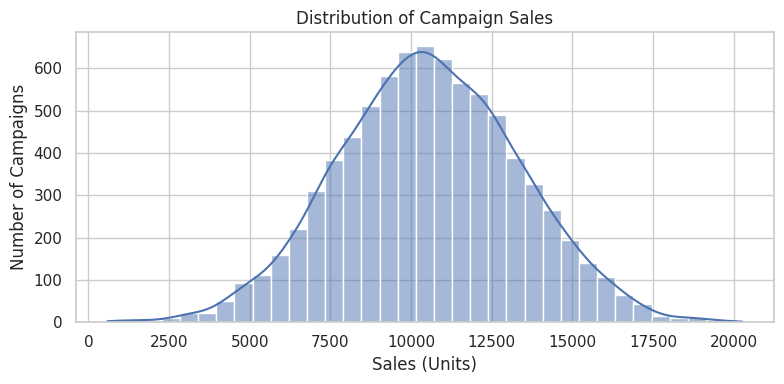

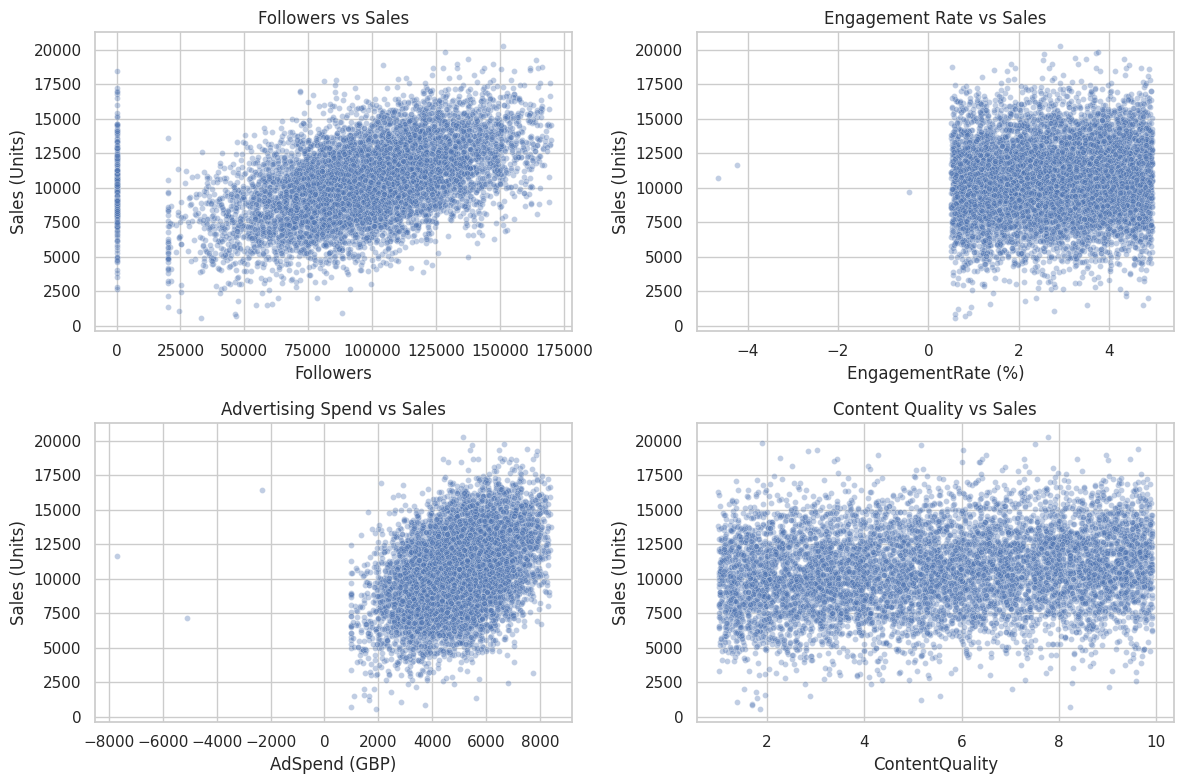

,Followers,EngagementRate (%),AdSpend (GBP),ContentQuality,Sales (Units)
Followers,1.000,-0.008,-0.000,0.002,0.016
EngagementRate (%),-0.008,1.000,0.004,-0.017,0.078
AdSpend (GBP),-0.000,0.004,1.000,0.017,0.003
ContentQuality,0.002,-0.017,0.017,1.000,0.169
Sales (Units),0.016,0.078,0.003,0.169,1.000


In [26]:

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

sns.set_theme(style="whitegrid")

# 1. Inspect extreme values
print("EXTREME VALUE CHECK")
for col in ["Followers", "EngagementRate (%)", "AdSpend (GBP)", "ContentQuality"]:
    s = train[col].dropna()
    print(f"\n{col}")
    print("Negative values:", (s < 0).sum())
    print("99th percentile:", round(s.quantile(0.99), 3))
    print("99.9th percentile:", round(s.quantile(0.999), 3))
    print("Maximum:", round(s.max(), 3))

# 2. Inspect the most extreme observations
print("\nTOP 10 FOLLOWER VALUES")
display(train.nlargest(10, "Followers")[
    ["Followers", "EngagementRate (%)", "AdSpend (GBP)",
     "ContentQuality", "Sales (Units)", "Timestamp"]
])

print("\nTOP 10 AD SPEND VALUES")
display(train.nlargest(10, "AdSpend (GBP)")[
    ["Followers", "EngagementRate (%)", "AdSpend (GBP)",
     "ContentQuality", "Sales (Units)", "Timestamp"]
])

# 3. Check identifier quality and date coverage
print("\nDuplicate IDs in training:", train["ID"].duplicated().sum())
print("Training date range:", train["Timestamp"].min(), "to", train["Timestamp"].max())
print("Test date range:", test["Timestamp"].min(), "to", test["Timestamp"].max())

# 4. Visualise the target distribution
plt.figure(figsize=(8, 4))
sns.histplot(train["Sales (Units)"], bins=35, kde=True)
plt.title("Distribution of Campaign Sales")
plt.xlabel("Sales (Units)")
plt.ylabel("Number of Campaigns")
plt.tight_layout()
plt.show()

# 5. Compare campaign features with sales
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

features = [
    ("Followers", "Followers vs Sales"),
    ("EngagementRate (%)", "Engagement Rate vs Sales"),
    ("AdSpend (GBP)", "Advertising Spend vs Sales"),
    ("ContentQuality", "Content Quality vs Sales")
]

for ax, (col, title) in zip(axes.flatten(), features):
    plot_data = train[[col, "Sales (Units)"]].dropna()
    # Restrict the visualisation to the central 99% of the feature
    upper = plot_data[col].quantile(0.99)
    plot_data = plot_data[plot_data[col] <= upper]
    sns.scatterplot(
        data=plot_data, x=col, y="Sales (Units)",
        alpha=0.35, s=18, ax=ax
    )
    ax.set_title(title)

plt.tight_layout()
plt.show()

# 6. Correlations (exploratory, not proof of causation)
corr_cols = [
    "Followers", "EngagementRate (%)", "AdSpend (GBP)",
    "ContentQuality", "Sales (Units)"
]
display(train[corr_cols].corr().round(3))


In [27]:

# STEP 1: Inspect the training and test datasets

import pandas as pd
import numpy as np

# Standardize column names by removing extra spaces
train.columns = train.columns.str.strip()
test.columns = test.columns.str.strip()

TARGET = "Sales (Units)"

print("TRAINING DATA SHAPE:", train.shape)
print("TEST DATA SHAPE:", test.shape)

print("\nTRAINING COLUMNS:")
print(train.columns.tolist())

print("\nTEST COLUMNS:")
print(test.columns.tolist())

print("\nMISSING VALUES IN TRAINING DATA:")
print(train.isnull().sum())

print("\nDATA TYPES:")
print(train.dtypes)

print("\nTARGET SUMMARY:")
print(train[TARGET].describe())

print("\nFIRST FIVE ROWS:")
display(train.head())


TRAINING DATA SHAPE: (8000, 12)
TEST DATA SHAPE: (2000, 11)

TRAINING COLUMNS:
['Followers', 'EngagementRate (%)', 'AdSpend (GBP)', 'ContentQuality', 'Sales (Units)', 'ID', 'Timestamp', 'Notes', 'Year', 'Month', 'DayOfWeek', 'Quarter']

TEST COLUMNS:
['Followers', 'EngagementRate (%)', 'AdSpend (GBP)', 'ContentQuality', 'ID', 'Timestamp', 'Notes', 'Year', 'Month', 'DayOfWeek', 'Quarter']

MISSING VALUES IN TRAINING DATA:
Followers              160
EngagementRate (%)     160
AdSpend (GBP)          159
ContentQuality         160
Sales (Units)            0
ID                       0
Timestamp                0
Notes                 2652
Year                     0
Month                    0
DayOfWeek                0
Quarter                  0
dtype: int64

DATA TYPES:
Followers                    Float64
EngagementRate (%)           Float64
AdSpend (GBP)                Float64
ContentQuality               Float64
Sales (Units)                  int64
ID                             int64
Tim

,Followers,EngagementRate (%),AdSpend (GBP),ContentQuality,Sales (Units),ID,Timestamp,Notes,Year,Month,DayOfWeek,Quarter
0,106572.0,2.573175,2614.378195,5.27568,6340,9254,2021-11-27,pending,2021,11,5,4
1,77583.0,0.939498,4975.962514,8.756268,5793,1561,2022-02-13,review,2022,2,6,1
2,92832.0,2.176101,4107.769534,6.454727,8104,1670,2023-09-25,pending,2023,9,0,3
3,53565.0,1.478376,4293.330465,4.312813,7293,6087,2023-02-15,review,2023,2,2,1
4,121079.0,3.374198,5343.549441,3.769047,14396,6669,2023-05-28,<NA>,2023,5,6,2


In [28]:

# STEP 2: Clean data without deleting useful records

train_clean = train.copy()
test_clean = test.copy()

# Remove duplicate rows, if any
train_clean = train_clean.drop_duplicates().reset_index(drop=True)
test_clean = test_clean.drop_duplicates().reset_index(drop=True)

# Identify numerical columns that should not be negative
nonnegative_columns = [
    "Followers",
    "EngagementRate (%)",
    "AdSpend (GBP)"
]

for col in nonnegative_columns:
    if col in train_clean.columns:
        train_clean[col] = pd.to_numeric(
            train_clean[col].astype(str).str.replace(
                ",", "", regex=False
            ).str.replace("£", "", regex=False)
             .str.replace("%", "", regex=False),
            errors="coerce"
        )

        test_clean[col] = pd.to_numeric(
            test_clean[col].astype(str).str.replace(
                ",", "", regex=False
            ).str.replace("£", "", regex=False)
             .str.replace("%", "", regex=False),
            errors="coerce"
        )

        # Treat impossible negative values as missing
        train_clean.loc[train_clean[col] < 0, col] = np.nan
        test_clean.loc[test_clean[col] < 0, col] = np.nan

# Convert target to numeric
train_clean[TARGET] = pd.to_numeric(
    train_clean[TARGET], errors="coerce"
)

# Target values must be available for supervised learning
train_clean = train_clean.dropna(subset=[TARGET])

print("Cleaned training shape:", train_clean.shape)
print("Cleaned test shape:", test_clean.shape)
print("\nRemaining missing values:")
display(train_clean.isnull().sum())


Cleaned training shape: (8000, 12)
Cleaned test shape: (2000, 11)

Remaining missing values:


,0
Followers,160
EngagementRate (%),163
AdSpend (GBP),162
ContentQuality,160
Sales (Units),0
ID,0
Timestamp,0
Notes,2652
Year,0
Month,0


Duplicate training rows: 0

Sales statistics:


,Sales (Units)
count,8000.000000
mean,10544.674375
std,2808.151485
min,590.000000
25%,8642.250000
50%,10500.000000
75%,12459.000000
max,20263.000000


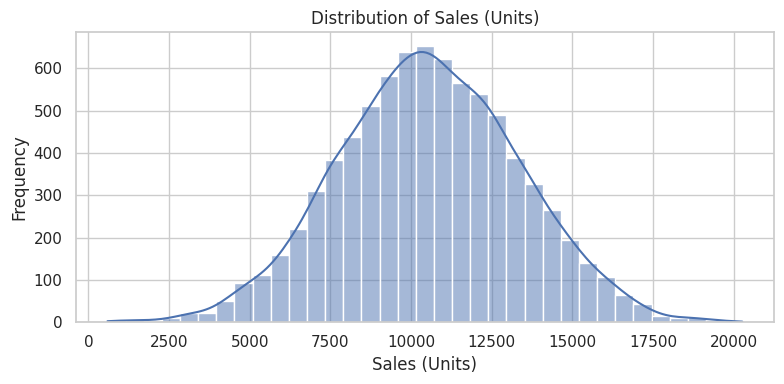

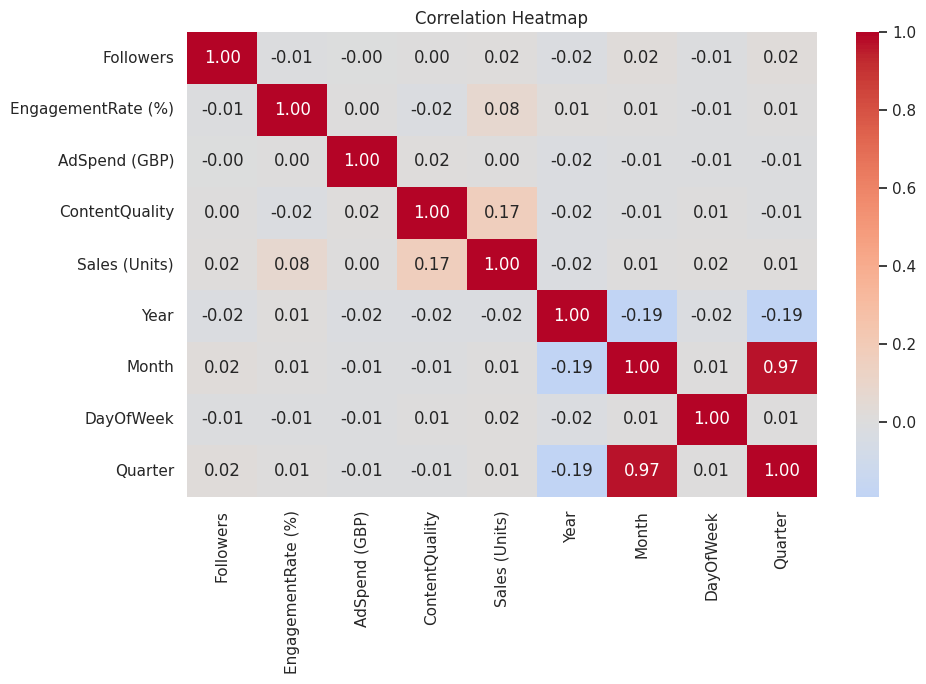

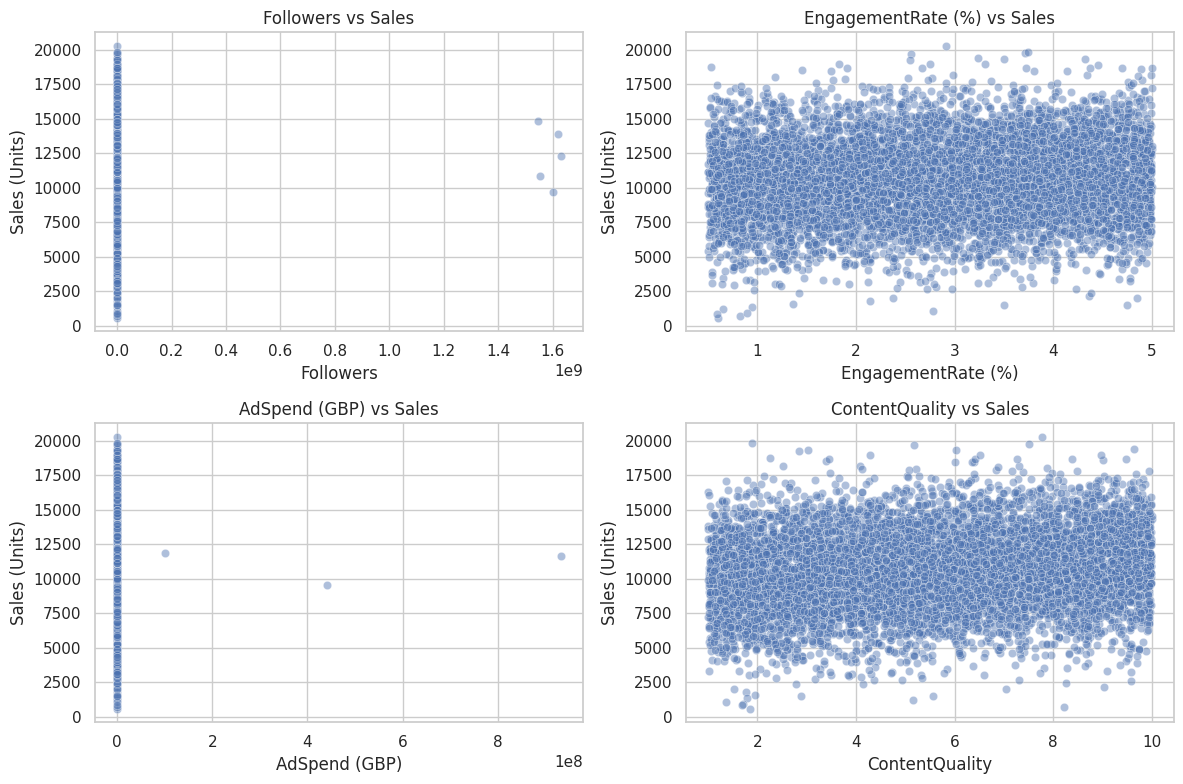

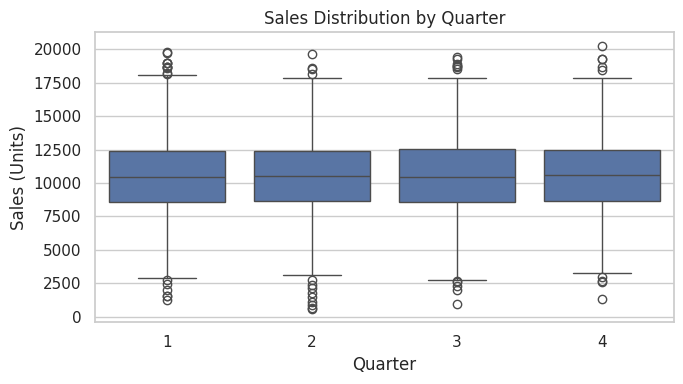

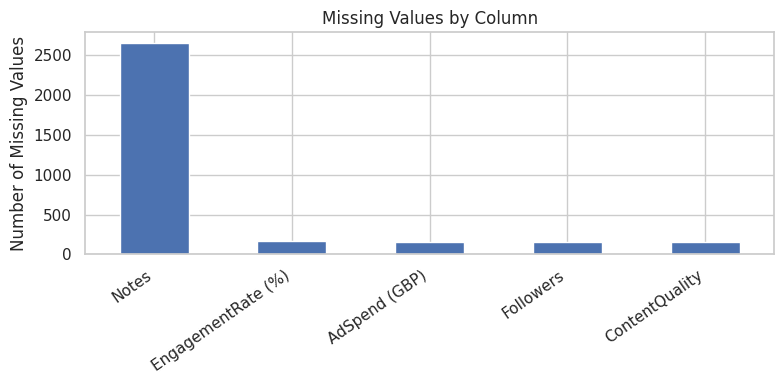

In [29]:

# STEP 4: Exploratory Data Analysis

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

sns.set_theme(style="whitegrid")

# 1. Check duplicates and target distribution
print("Duplicate training rows:", train_clean.duplicated().sum())
print("\nSales statistics:")
display(train_clean[TARGET].describe().to_frame())

plt.figure(figsize=(8, 4))
sns.histplot(train_clean[TARGET], kde=True, bins=35)
plt.title("Distribution of Sales (Units)")
plt.xlabel("Sales (Units)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

# 2. Correlation between numerical variables
numeric_cols = [
    "Followers",
    "EngagementRate (%)",
    "AdSpend (GBP)",
    "ContentQuality",
    "Sales (Units)",
    "Year",
    "Month",
    "DayOfWeek",
    "Quarter"
]

corr = train_clean[numeric_cols].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

# 3. Relationship between key predictors and sales
features_to_plot = [
    "Followers",
    "EngagementRate (%)",
    "AdSpend (GBP)",
    "ContentQuality"
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for col, ax in zip(features_to_plot, axes.flatten()):
    sns.scatterplot(
        data=train_clean,
        x=col,
        y=TARGET,
        alpha=0.45,
        ax=ax
    )
    ax.set_title(f"{col} vs Sales")

plt.tight_layout()
plt.show()

# 4. Sales by quarter
plt.figure(figsize=(7, 4))
sns.boxplot(data=train_clean, x="Quarter", y=TARGET)
plt.title("Sales Distribution by Quarter")
plt.tight_layout()
plt.show()

# 5. Missing values visualisation
missing = train_clean.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

plt.figure(figsize=(8, 4))
missing.plot(kind="bar")
plt.title("Missing Values by Column")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


In [30]:

# STEP 5: Train-validation split and preprocessing

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Features selected for the initial models
numeric_features = [
    "Followers",
    "EngagementRate (%)",
    "AdSpend (GBP)",
    "ContentQuality",
    "Year",
    "Month",
    "DayOfWeek",
    "Quarter"
]

categorical_features = ["Notes"]

X = train_clean[numeric_features + categorical_features].copy()
y = train_clean[TARGET].astype(float).copy()

X_test = test_clean[numeric_features + categorical_features].copy()

# Convert numerical columns to standard numeric types
for col in numeric_features:
    X[col] = pd.to_numeric(X[col], errors="coerce").astype(float)
    X_test[col] = pd.to_numeric(
        X_test[col], errors="coerce"
    ).astype(float)

# Handle missing categorical values consistently
for data in [X, X_test]:
    data["Notes"] = data["Notes"].astype(object)
    data["Notes"] = data["Notes"].where(
        data["Notes"].notna(), np.nan
    )

# Split only the labelled training data
X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

# Impute numerical and categorical features separately
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

print("Training rows:", X_train.shape[0])
print("Validation rows:", X_val.shape[0])
print("Test rows:", X_test.shape[0])
print("Features:", len(numeric_features) + len(categorical_features))
print("Missing values will be handled within each pipeline.")


Training rows: 6400
Validation rows: 1600
Test rows: 2000
Features: 9
Missing values will be handled within each pipeline.


In [31]:

# STEP 6: Model training and validation

models = {
    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )
}

results = []
fitted_models = {}

for name, estimator in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_val)

    mae = mean_absolute_error(y_val, predictions)
    rmse = np.sqrt(mean_squared_error(y_val, predictions))
    r2 = r2_score(y_val, predictions)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    fitted_models[name] = pipeline

results_df = pd.DataFrame(results).sort_values("RMSE")

print("MODEL COMPARISON — LOWER MAE/RMSE AND HIGHER R² ARE BETTER")
display(results_df.round(3))

best_model_name = results_df.iloc[0]["Model"]
best_model = fitted_models[best_model_name]

print("Best initial model:", best_model_name)


MODEL COMPARISON — LOWER MAE/RMSE AND HIGHER R² ARE BETTER


,Model,MAE,RMSE,R2
1,Random Forest,1691.233,2117.427,0.436
2,Extra Trees,1692.656,2136.692,0.425
0,Linear Regression,2234.171,2788.290,0.022


Best initial model: Random Forest


In [32]:

# STEP 8: Random Forest hyperparameter tuning

from sklearn.model_selection import RandomizedSearchCV
from sklearn.base import clone
from scipy.stats import randint

rf_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ))
])

param_distributions = {
    "model__n_estimators": [200, 300, 400],
    "model__max_depth": [None, 10, 15, 20, 25],
    "model__min_samples_split": [2, 5, 10, 15],
    "model__min_samples_leaf": [1, 2, 4, 6],
    "model__max_features": [0.6, 0.8, 1.0]
}

random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_distributions,
    n_iter=15,
    scoring="neg_root_mean_squared_error",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)

random_search.fit(X_train, y_train)

tuned_model = random_search.best_estimator_
tuned_predictions = tuned_model.predict(X_val)

tuned_mae = mean_absolute_error(y_val, tuned_predictions)
tuned_rmse = np.sqrt(mean_squared_error(y_val, tuned_predictions))
tuned_r2 = r2_score(y_val, tuned_predictions)

print("\nBEST PARAMETERS:")
print(random_search.best_params_)

print("\nBEST CROSS-VALIDATION RMSE:")
print(round(-random_search.best_score_, 3))

print("\nVALIDATION PERFORMANCE:")
print("MAE:", round(tuned_mae, 3))
print("RMSE:", round(tuned_rmse, 3))
print("R2:", round(tuned_r2, 4))

print("\nINITIAL VS TUNED RANDOM FOREST")
display(pd.DataFrame([
    {
        "Model": "Initial Random Forest",
        "MAE": results_df.loc[
            results_df["Model"] == "Random Forest", "MAE"
        ].iloc[0],
        "RMSE": results_df.loc[
            results_df["Model"] == "Random Forest", "RMSE"
        ].iloc[0],
        "R2": results_df.loc[
            results_df["Model"] == "Random Forest", "R2"
        ].iloc[0]
    },
    {
        "Model": "Tuned Random Forest",
        "MAE": tuned_mae,
        "RMSE": tuned_rmse,
        "R2": tuned_r2
    }
]).round(3))


Fitting 3 folds for each of 15 candidates, totalling 45 fits

BEST PARAMETERS:
{'model__n_estimators': 200, 'model__min_samples_split': 10, 'model__min_samples_leaf': 1, 'model__max_features': 0.8, 'model__max_depth': 10}

BEST CROSS-VALIDATION RMSE:
2049.964

VALIDATION PERFORMANCE:
MAE: 1669.777
RMSE: 2093.811
R2: 0.4483

INITIAL VS TUNED RANDOM FOREST


,Model,MAE,RMSE,R2
0,Initial Random Forest,1691.233,2117.427,0.436
1,Tuned Random Forest,1669.777,2093.811,0.448


,Actual Sales,Predicted Sales,Residual
0,12895.0,10262.39,2632.61
1,16217.0,11316.81,4900.19
2,15489.0,11823.02,3665.98
3,16238.0,10017.58,6220.42
4,10930.0,8000.91,2929.09
5,11442.0,8329.21,3112.79
6,11586.0,13115.94,-1529.94
7,8754.0,10027.76,-1273.76
8,7117.0,8493.98,-1376.98
9,11553.0,9997.00,1556.00


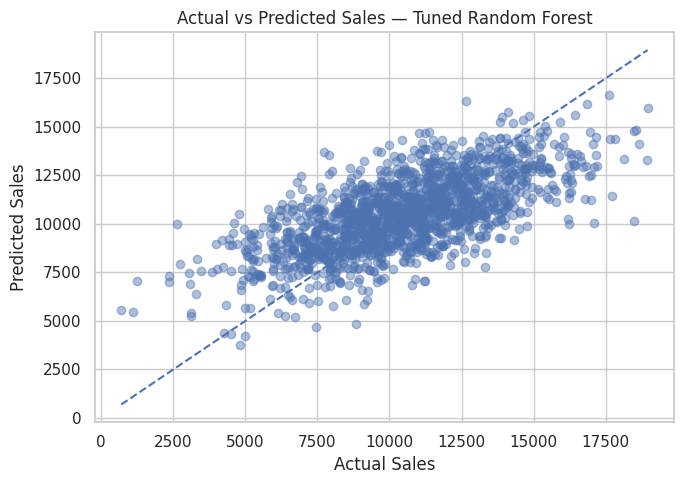

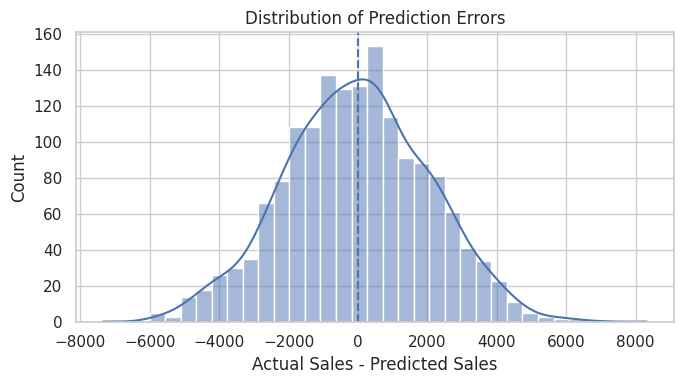

In [33]:

# STEP 9: Actual vs predicted sales and residual analysis

comparison = pd.DataFrame({
    "Actual Sales": y_val.to_numpy(),
    "Predicted Sales": tuned_predictions
})

comparison["Residual"] = (
    comparison["Actual Sales"] - comparison["Predicted Sales"]
)

display(comparison.head(10).round(2))

# Actual vs predicted
plt.figure(figsize=(7, 5))
plt.scatter(
    comparison["Actual Sales"],
    comparison["Predicted Sales"],
    alpha=0.45
)

lower = min(
    comparison["Actual Sales"].min(),
    comparison["Predicted Sales"].min()
)
upper = max(
    comparison["Actual Sales"].max(),
    comparison["Predicted Sales"].max()
)

plt.plot([lower, upper], [lower, upper], linestyle="--")
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales — Tuned Random Forest")
plt.tight_layout()
plt.show()

# Residual distribution
plt.figure(figsize=(7, 4))
sns.histplot(comparison["Residual"], kde=True, bins=35)
plt.axvline(0, linestyle="--")
plt.title("Distribution of Prediction Errors")
plt.xlabel("Actual Sales - Predicted Sales")
plt.tight_layout()
plt.show()


In [34]:

# STEP 10: Compare models with and without Notes (FIXED)

from sklearn.base import clone

# Model using Notes
rf_with_notes = clone(tuned_model)
rf_with_notes.fit(X_train, y_train)
pred_with_notes = rf_with_notes.predict(X_val)

# Build a numerical-only preprocessing pipeline
numeric_only_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

rf_without_notes = Pipeline([
    ("preprocessor", numeric_only_preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=best_params["model__n_estimators"],
        max_depth=best_params["model__max_depth"],
        min_samples_split=best_params["model__min_samples_split"],
        min_samples_leaf=best_params["model__min_samples_leaf"],
        max_features=best_params["model__max_features"],
        random_state=42,
        n_jobs=-1
    ))
])

rf_without_notes.fit(
    X_train[numeric_features],
    y_train
)

pred_without_notes = rf_without_notes.predict(
    X_val[numeric_features]
)

# Compare performance
notes_comparison = pd.DataFrame([
    {
        "Features": "With Notes",
        "MAE": mean_absolute_error(y_val, pred_with_notes),
        "RMSE": np.sqrt(mean_squared_error(y_val, pred_with_notes)),
        "R2": r2_score(y_val, pred_with_notes)
    },
    {
        "Features": "Without Notes",
        "MAE": mean_absolute_error(y_val, pred_without_notes),
        "RMSE": np.sqrt(mean_squared_error(y_val, pred_without_notes)),
        "R2": r2_score(y_val, pred_without_notes)
    }
]).sort_values("RMSE")

display(notes_comparison.round(3))

# Automatically select the better validation model
if notes_comparison.iloc[0]["Features"] == "With Notes":
    final_model = rf_with_notes
    print("Selected model: Random Forest with Notes")
else:
    final_model = rf_without_notes
    print("Selected model: Random Forest without Notes")


,Features,MAE,RMSE,R2
1,Without Notes,1666.183,2086.664,0.452
0,With Notes,1669.777,2093.811,0.448


Selected model: Random Forest without Notes


,Feature,Importance
0,numeric__Followers,0.4680
2,numeric__AdSpend (GBP),0.3036
3,numeric__ContentQuality,0.0995
1,numeric__EngagementRate (%),0.0622
5,numeric__Month,0.0220
6,numeric__DayOfWeek,0.0178
4,numeric__Year,0.0071
7,numeric__Quarter,0.0052
10,categorical__Notes_pending,0.0043
9,categorical__Notes_good,0.0036


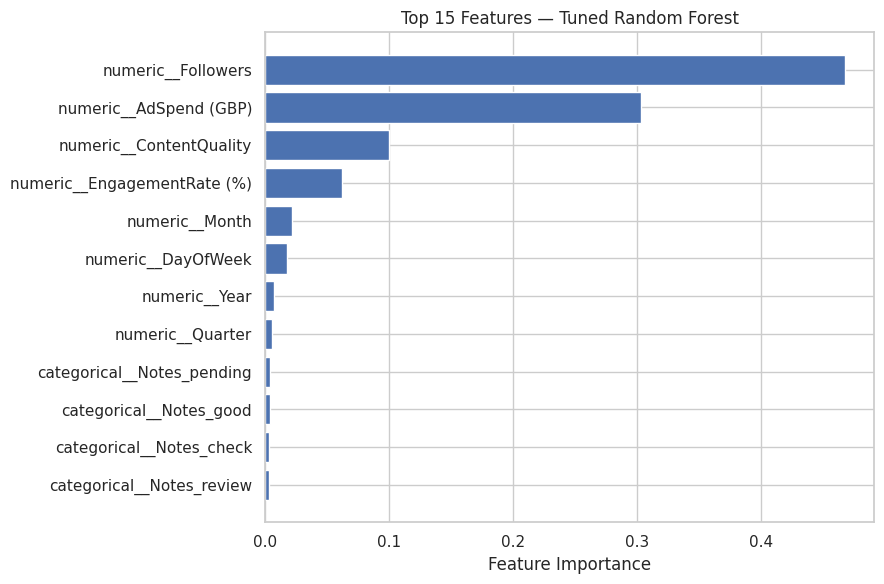

In [35]:

# STEP 11: Feature importance

fitted_preprocessor = tuned_model.named_steps["preprocessor"]
fitted_rf = tuned_model.named_steps["model"]

feature_names = fitted_preprocessor.get_feature_names_out()
importances = fitted_rf.feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

# Display the top 15 features
display(importance_df.head(15).round(4))

plt.figure(figsize=(9, 6))
top_features = importance_df.head(15).sort_values("Importance")

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.title("Top 15 Features — Tuned Random Forest")
plt.tight_layout()
plt.show()


In [36]:

# STEP 12: Generate final predictions using the selected model

# Prepare test features consistently
X_test_numeric = X_test[numeric_features].copy()

final_predictions = final_model.predict(X_test_numeric)

submission = pd.DataFrame({
    "ID": test_clean["ID"].to_numpy(),
    "Predicted Sales (Units)": np.maximum(
        0, final_predictions
    ).round().astype(int)
})

print("Number of predictions:", len(submission))
print("\nPrediction summary:")
display(submission["Predicted Sales (Units)"].describe().to_frame())

print("\nFirst 10 predictions:")
display(submission.head(10))

submission.to_csv(
    "campaign_sales_predictions.csv",
    index=False
)

print("\nSaved successfully: campaign_sales_predictions.csv")


Number of predictions: 2000

Prediction summary:


,Predicted Sales (Units)
count,2000.000000
mean,10461.093500
std,1982.810127
min,4035.000000
25%,9053.750000
50%,10470.000000
75%,11732.500000
max,16199.000000



First 10 predictions:


,ID,Predicted Sales (Units)
0,6252,13168
1,4684,8594
2,1731,10374
3,4742,10273
4,4521,11871
5,6340,9515
6,576,11415
7,5202,11273
8,6363,12778
9,439,12897



Saved successfully: campaign_sales_predictions.csv


In [37]:

# STEP 13: Save the trained model

import joblib

joblib.dump(final_model, "campaign_sales_model.joblib")

print("Model saved successfully: campaign_sales_model.joblib")


Model saved successfully: campaign_sales_model.joblib


In [38]:

# STEP 14: Final validation metrics

final_val_predictions = final_model.predict(
    X_val[numeric_features]
)

final_mae = mean_absolute_error(
    y_val, final_val_predictions
)

final_rmse = np.sqrt(
    mean_squared_error(y_val, final_val_predictions)
)

final_r2 = r2_score(
    y_val, final_val_predictions
)

final_metrics = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R²"],
    "Value": [final_mae, final_rmse, final_r2]
})

display(final_metrics.round(4))

print(
    f"Final model: Random Forest without Notes\n"
    f"Validation MAE: {final_mae:.2f} units\n"
    f"Validation RMSE: {final_rmse:.2f} units\n"
    f"Validation R²: {final_r2:.4f}"
)


,Metric,Value
0,MAE,1666.1830
1,RMSE,2086.6642
2,R²,0.4520


Final model: Random Forest without Notes
Validation MAE: 1666.18 units
Validation RMSE: 2086.66 units
Validation R²: 0.4520


,Feature,Importance
0,Followers,0.4726
2,AdSpend (GBP),0.3045
3,ContentQuality,0.1022
1,EngagementRate (%),0.0663
5,Month,0.0223
6,DayOfWeek,0.0194
4,Year,0.0076
7,Quarter,0.0051


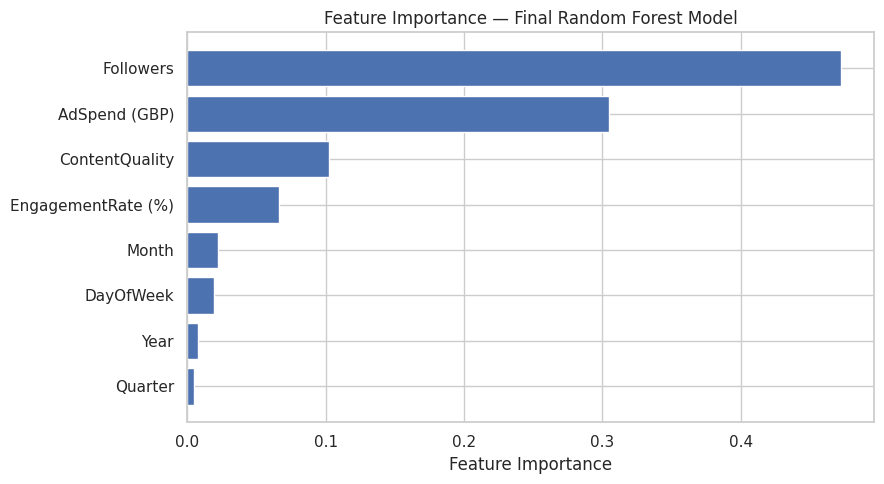

In [39]:

# STEP 15: Feature importance for the final model

importance_df = pd.DataFrame({
    "Feature": numeric_features,
    "Importance": final_model.named_steps["model"].feature_importances_
}).sort_values("Importance", ascending=False)

display(importance_df.round(4))

plt.figure(figsize=(9, 5))
plt.barh(
    importance_df.sort_values("Importance")["Feature"],
    importance_df.sort_values("Importance")["Importance"]
)
plt.xlabel("Feature Importance")
plt.title("Feature Importance — Final Random Forest Model")
plt.tight_layout()
plt.show()


# Predicting Sales from Campaign Data

## 1. Project Objective

The objective of this project is to develop a machine learning model that predicts product sales using influencer marketing campaign data. The analysis investigates whether follower count, engagement rate, advertising expenditure, content quality, and calendar-related variables can help estimate sales and support marketing decisions.

## 2. Dataset Overview

The training dataset contains 8,000 records and 12 columns, including the sales target. The test dataset contains 2,000 records and 11 columns, without the target variable. The target variable is `Sales (Units)`.

The training target has a mean of 10,544.67 units, a median of 10,500 units, and a standard deviation of 2,808.15 units. The recorded sales range from 590 to 20,263 units.

## 3. Data Cleaning and Preprocessing

The dataset was inspected for missing values, duplicates, data types, and invalid numerical values. Missing values in the principal numerical predictors were handled using median imputation within the machine learning pipeline. The `Notes` column contained substantial missing information and was evaluated separately.

The final model excluded the `ID`, raw timestamp, and `Notes` columns. Calendar variables extracted from the timestamp were retained. Excluding the identifier reduced the risk of the model relying on arbitrary record identifiers.

## 4. Exploratory Data Analysis

Exploratory data analysis included examination of the target distribution, correlations between numerical variables, relationships between the main campaign features and sales, quarterly sales distributions, and missing-value patterns.

These analyses were used to understand the data and identify potential relationships before model training. Correlation and feature importance are interpreted as indicators of association or predictive usefulness, not proof of causation.

## 5. Model Development

Three regression algorithms were evaluated: Linear Regression, Random Forest Regressor, and Extra Trees Regressor. The data was divided into training and validation subsets using an 80:20 split with a fixed random seed.

Random Forest achieved the strongest initial performance. Hyperparameter tuning was then performed using randomized search with three-fold cross-validation and negative root mean squared error as the optimization metric.

The selected hyperparameters were 200 trees, a maximum depth of 10, a minimum split size of 10, a minimum leaf size of 1, and a maximum feature fraction of 0.8.

## 6. Model Evaluation

The final selected model was Random Forest without the `Notes` feature.

| Metric | Validation result |
|---|---:|
| Mean Absolute Error (MAE) | 1,666.18 |
| Root Mean Squared Error (RMSE) | 2,086.66 |
| R-squared (R²) | 0.4520 |

The MAE indicates an average absolute prediction error of approximately 1,666 sales units on the validation set. RMSE penalizes larger errors more strongly and was approximately 2,087 units.

The R² value indicates that the model explains approximately 45.2% of the variation in validation sales. The result demonstrates useful predictive signal, although substantial variation remains unexplained.

## 7. Feature Selection

The model using numerical campaign and calendar features performed slightly better than the corresponding model including `Notes`.

The model without `Notes` achieved an RMSE of 2,086.66, compared with 2,093.81 when `Notes` was included. Therefore, the simpler numerical-feature model was selected.

The feature-importance analysis provides additional information about the variables most useful to the trained Random Forest. These results should be interpreted as model-specific predictive importance rather than causal effects.

## 8. Test Predictions

The selected model generated predictions for all 2,000 records in the test dataset. The predictions had a mean of 10,461.09 units, a standard deviation of 1,982.81 units, a minimum of 4,035 units, and a maximum of 16,199 units.

The predictions were saved in `campaign_sales_predictions.csv`, with the corresponding record identifier and predicted sales. The trained pipeline was saved as `campaign_sales_model.joblib`.

Because actual sales labels were unavailable for the test dataset, its prediction accuracy could not be directly measured.

## 9. Business Recommendations

Marketing teams can use the model as an initial decision-support tool for estimating campaign sales. Campaign characteristics identified as important by the model can help guide further investigation into creator selection, engagement, advertising budgets, and content strategy.

Predictions should be combined with campaign costs, product margins, audience relevance, and conversion data before making budget-allocation decisions. A predicted sales figure alone does not establish campaign profitability.

Before operational deployment, the model should be evaluated on additional unseen data, monitored for changes in performance, and compared against a simple baseline. Marketing experiments are recommended to establish whether changes in campaign strategy cause improvements in sales.

## 10. Limitations

The model explains 45.2% of validation sales variation, so predictions contain meaningful uncertainty. The dataset may omit important factors such as product category, pricing, discounts, inventory, audience demographics, creator authenticity, and conversion rates.

Random splitting may not fully represent future campaigns. A time-based validation strategy would be useful if the intended application is to forecast future sales. The dataset also contains unusual and potentially invalid values that require domain-specific review.

Feature importance does not establish causation, and the model has not been evaluated against actual test-set labels.

## 11. Conclusion

This project developed and evaluated a machine learning pipeline for predicting sales from campaign data. Random Forest outperformed the tested baseline models, and hyperparameter tuning produced a modest improvement. Removing the `Notes` feature resulted in a further small improvement on the validation set.

The final model achieved an MAE of 1,666.18 units, an RMSE of 2,086.66 units, and an R² of 0.4520. Predictions were generated for 2,000 test records, and the model and prediction files were saved.

The results provide a foundation for campaign-sales forecasting and further experimentation. Better performance will require additional predictive information, robust validation, and continued evaluation against actual campaign outcomes.

## 12. Feature Importance and Business Interpretation

The feature-importance analysis identifies Followers as the most influential predictor in the final Random Forest model, with an importance score of 0.4726 (47.26%). Advertising spend is the second most influential feature at 30.45%, followed by ContentQuality at 10.22% and EngagementRate (%) at 6.63%.

Together, these four campaign-related variables account for approximately 93.56% of the model's total feature importance. Calendar variables have comparatively lower importance, suggesting that campaign characteristics provide more predictive information than the calendar features in this model.

From a business perspective, the results suggest that audience reach and advertising expenditure deserve particular attention when estimating campaign sales. Content quality and engagement should also be monitored because they contribute additional predictive information.

However, feature importance does not establish that increasing followers or advertising spend will necessarily increase sales. The scores describe how the fitted model uses the available variables and may be affected by relationships between predictors, data quality, and the characteristics of the dataset. Marketing teams should combine these findings with profitability analysis and controlled experiments before changing budgets or selecting creators.


In [40]:

# STEP 16: Compare Original and Feature-Engineered Models

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Prepare features and target
X_base = train_clean[numeric_features].copy()
y_base = train_clean["Sales (Units)"].copy()

# Ensure target values are numeric
y_base = pd.to_numeric(y_base, errors="coerce")

# Remove rows with missing target values
valid_rows = y_base.notna()
X_base = X_base.loc[valid_rows].reset_index(drop=True)
y_base = y_base.loc[valid_rows].reset_index(drop=True)

# Split data consistently for both models
train_idx, val_idx = train_test_split(
    np.arange(len(y_base)),
    test_size=0.20,
    random_state=42
)

# Common model settings
rf_settings = {
    "n_estimators": 200,
    "min_samples_split": 10,
    "min_samples_leaf": 1,
    "max_features": 0.8,
    "max_depth": 10,
    "random_state": 42,
    "n_jobs": -1
}

# Model 1: Original features
base_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestRegressor(**rf_settings))
])

base_model.fit(X_base.iloc[train_idx], y_base.iloc[train_idx])
base_pred = base_model.predict(X_base.iloc[val_idx])

# Model 2: Feature-engineered features
X_eng = X_base.copy()

for col in ["Followers", "AdSpend (GBP)"]:
    X_eng.loc[X_eng[col] < 0, col] = np.nan
    X_eng[f"log_{col}"] = np.log1p(X_eng[col])

X_eng["Followers_x_Engagement"] = (
    X_eng["Followers"] * X_eng["EngagementRate (%)"]
)

X_eng["Spend_x_Engagement"] = (
    X_eng["AdSpend (GBP)"] * X_eng["EngagementRate (%)"]
)

engineered_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestRegressor(**rf_settings))
])

engineered_model.fit(X_eng.iloc[train_idx], y_base.iloc[train_idx])
eng_pred = engineered_model.predict(X_eng.iloc[val_idx])

# Compare performance
results_df = pd.DataFrame([
    {
        "Model": "Original Random Forest",
        "MAE": mean_absolute_error(y_base.iloc[val_idx], base_pred),
        "RMSE": np.sqrt(mean_squared_error(y_base.iloc[val_idx], base_pred)),
        "R2": r2_score(y_base.iloc[val_idx], base_pred)
    },
    {
        "Model": "Feature-Engineered Random Forest",
        "MAE": mean_absolute_error(y_base.iloc[val_idx], eng_pred),
        "RMSE": np.sqrt(mean_squared_error(y_base.iloc[val_idx], eng_pred)),
        "R2": r2_score(y_base.iloc[val_idx], eng_pred)
    }
])

display(results_df.round(3))


,Model,MAE,RMSE,R2
0,Original Random Forest,1666.176,2086.616,0.452
1,Feature-Engineered Random Forest,1676.738,2095.349,0.447


### Feature Engineering and Model Comparison

Feature engineering was performed by applying logarithmic transformations to the Followers and AdSpend variables and creating interaction features between engagement rate and campaign reach or advertising spend.

The original Random Forest model achieved an MAE of 1666.176, RMSE of 2086.616, and R² of 0.452. The feature-engineered model achieved an MAE of 1676.738, RMSE of 2095.349, and R² of 0.447.

The results indicate that the engineered features did not improve predictive performance on the validation dataset. Therefore, the original feature set was retained for the final model. This comparison demonstrates that feature engineering should be evaluated empirically rather than assumed to improve accuracy.

In [41]:

# STEP 17: Reusable prediction function for messy campaign data

def predict_campaign_sales(new_data):
    """
    Predict sales for new campaign records.

    Accepts a pandas DataFrame containing the original campaign
    features. Handles numeric strings, commas, currency symbols,
    percentage signs, missing values and negative numeric values.
    """
    data = new_data.copy()

    required_features = [
        "Followers",
        "EngagementRate (%)",
        "AdSpend (GBP)",
        "ContentQuality",
        "Year",
        "Month",
        "DayOfWeek",
        "Quarter"
    ]

    # Create any missing required columns
    for col in required_features:
        if col not in data.columns:
            data[col] = np.nan

    # Clean numeric fields
    for col in required_features:
        cleaned = (
            data[col]
            .astype("string")
            .str.replace(",", "", regex=False)
            .str.replace("£", "", regex=False)
            .str.replace("%", "", regex=False)
            .str.strip()
        )

        data[col] = pd.to_numeric(cleaned, errors="coerce")

    # Treat impossible negative values as missing for these fields
    for col in ["Followers", "EngagementRate (%)", "AdSpend (GBP)"]:
        data.loc[data[col] < 0, col] = np.nan

    # Use the saved model's preprocessing pipeline
    predictions = final_model.predict(data[required_features])

    return pd.DataFrame({
        "Predicted Sales (Units)": np.maximum(0, predictions).round().astype(int)
    })


# Demonstrate with a few test records
display(predict_campaign_sales(test_clean.head()))


,Predicted Sales (Units)
0,13168
1,8594
2,10374
3,10273
4,11871
